# Task 03: End-to-End Machine Learning Project
## Loan Default (Credit Risk) Prediction
**Devixo Solutions | AI/ML Internship Program**
**Author:** Aman Hameed Ullah
**Dataset:** Credit Risk Dataset (Kaggle)

## Table of Contents
1. Data Preparation
2. Model Development
3. Model Optimization
4. Saving the Best Model
5. Results, Limitations and Future Improvements
6. Bonus: Prediction Interface (Streamlit)

## 1. Data Preparation
### 1.0 Connecting Google Drive

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Google Drive was mounted so that the notebook can read the dataset and save charts and models in the project folder (`Task_03_AI_ML`).

### 1.1 Importing Libraries

In [5]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectFpr, f_classif

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

Pandas and NumPy are used for data handling, Matplotlib and Seaborn for charts, and Scikit-learn for the preprocessing pipeline, feature selection and (later) the models. Scikit-learn's `Pipeline` and `ColumnTransformer` allow all preprocessing steps to be combined with the model in one reusable object.

### 1.2 Importing the Dataset

In [6]:
PATH = '/content/drive/MyDrive/Task_03_AI_ML/dataset/credit_risk_dataset.csv'
IMG = '/content/drive/MyDrive/Task_03_AI_ML/images/'
os.makedirs(IMG, exist_ok=True)

df = pd.read_csv(PATH)
raw_rows, raw_cols = df.shape
pd.set_option('display.max_columns', None)
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


The Credit Risk dataset contains 32,581 loan applicants and 12 columns. Each row describes the borrower (age, income, home ownership, employment length), the loan (intent, grade, amount, interest rate, loan as a percentage of income) and the borrower's credit history. The target column `loan_status` shows whether the loan ended in default (1) or not (0). The goal is to predict default before a loan is granted.

### 1.3 Understanding the Target Variable

loan_status
0    25473
1     7108
Name: count, dtype: int64
loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


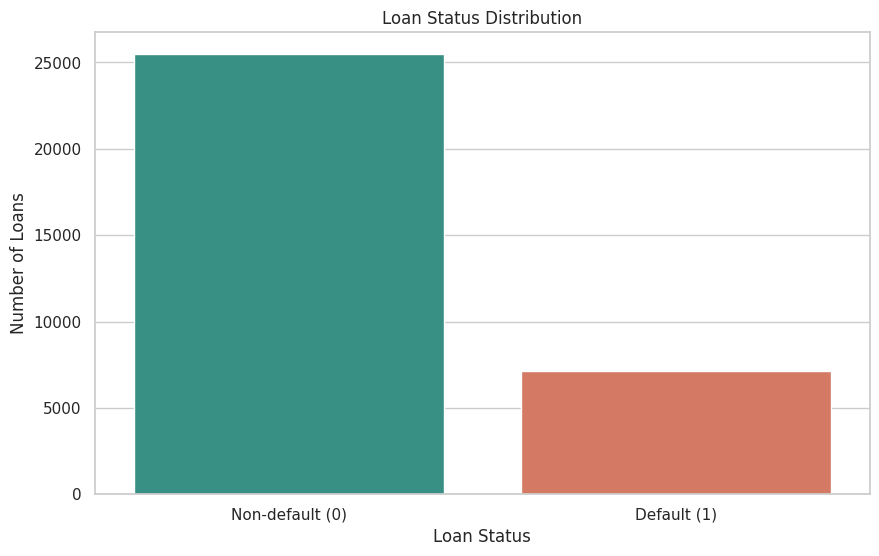

In [7]:
print(df['loan_status'].value_counts())
print((df['loan_status'].value_counts(normalize=True) * 100).round(2))

sns.countplot(x=df['loan_status'].map({0: 'Non-default (0)', 1: 'Default (1)'}),
              order=['Non-default (0)', 'Default (1)'], palette=['#2a9d8f', '#e76f51'])
plt.title('Loan Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Loans')
plt.show()

**Observation:** About 78.2% of the loans were repaid and about 21.8% ended in default, so the classes are imbalanced. A model that always predicts "no default" would already reach about 78% accuracy, which is why precision, recall and F1 score will be used together with accuracy in the evaluation.

### 1.4 Checking Missing Values and Unusual Values

In [8]:
missing = df.isnull().sum()
miss_df = pd.DataFrame({'Missing': missing, 'Percent': (missing / len(df) * 100).round(2)})
display(miss_df[miss_df['Missing'] > 0])
display(df.describe().T)

,Missing,Percent
person_emp_length,895,2.75
loan_int_rate,3116,9.56


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


**Observation:** Two columns contain missing values: `person_emp_length` (895 values, about 2.75%) and `loan_int_rate` (3,116 values, about 9.56%). The summary statistics also show impossible values: the maximum `person_age` is 144 years and the maximum `person_emp_length` is 123 years. These are data-entry errors and are handled in Section 1.6.

**Handling strategy:** the missing values are filled with the **median** inside the preprocessing pipeline (Section 1.9). The median is used because both columns are skewed and the median is not affected by extreme values. The imputer is fitted on the training data only, so no information from the test data leaks into training.

### 1.5 Removing Duplicate Records

In [9]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after removal:", df.duplicated().sum())
print("Shape:", df.shape)

Duplicate rows: 165
Duplicates after removal: 0
Shape: (32416, 12)


**Observation:** The dataset contained 165 duplicate rows (identical in every column). They were removed because duplicates give extra weight to the same record and could appear in both the training and the test set, which would make the test results look better than they are. After removal the duplicate count is 0 and 32,416 rows remain.

### 1.6 Handling Invalid Values

In [10]:
print("Age above 100:", (df['person_age'] > 100).sum())
print("Employment length above 60 years:", (df['person_emp_length'] > 60).sum())

before = len(df)
df = df[(df['person_age'] <= 100) &
        (df['person_emp_length'].isna() | (df['person_emp_length'] <= 60))].reset_index(drop=True)
print("Rows removed:", before - len(df))
print("Shape:", df.shape)

Age above 100: 5
Employment length above 60 years: 2
Rows removed: 7
Shape: (32409, 12)


**Observation:** 5 rows have an age above 100 (up to 144 years) and 2 rows have an employment length above 60 years (123 years), which are impossible values. Only 7 rows are affected, so they were removed instead of being guessed, leaving 32,409 rows. Very high incomes were kept, because they are possible and are real borrowers. Missing employment lengths were kept as missing and are imputed later.

### 1.7 Feature Engineering

In [11]:
df['emp_to_age_ratio'] = (df['person_emp_length'] / df['person_age']).round(4)
df['interest_cost'] = (df['loan_amnt'] * df['loan_int_rate'] / 100).round(2)
df['interest_to_income'] = (df['interest_cost'] / df['person_income']).round(4)
df['age_group'] = pd.cut(df['person_age'], bins=[0, 25, 35, 45, 100],
                         labels=['up to 25', '26-35', '36-45', '46+']).astype(str)

display(df[['emp_to_age_ratio', 'interest_cost', 'interest_to_income', 'age_group']].describe(include='all'))

,emp_to_age_ratio,interest_cost,interest_to_income,age_group
count,31522.000000,29315.000000,29315.000000,32409
unique,NaN,NaN,NaN,4
top,NaN,NaN,NaN,up to 25
freq,NaN,NaN,NaN,15243
mean,0.174022,1086.227084,0.019217,NaN
std,0.135270,878.672306,0.014311,NaN
min,0.000000,48.800000,0.000100,NaN
25%,0.064500,475.600000,0.008600,NaN
50%,0.142900,820.000000,0.015400,NaN
75%,0.272700,1423.200000,0.026100,NaN


Four new features were created from existing columns:
- `emp_to_age_ratio`: employment length divided by age, a measure of work stability.
- `interest_cost`: the yearly interest in currency units (loan amount × interest rate), the real cost of the loan.
- `interest_to_income`: the yearly interest divided by income, which shows how heavily the interest burdens the borrower.
- `age_group`: the borrower's age in four bands, so that models can find differences between age groups.

These features combine information that is spread over several columns and may help the models detect risky borrowers. They are calculated row by row, so creating them before the split does not leak information.

### 1.8 Splitting into Training and Testing Sets

In [12]:
TARGET = 'loan_status'
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Default rate train:", round(y_train.mean() * 100, 2), "% | test:", round(y_test.mean() * 100, 2), "%")

Train: (25927, 15) | Test: (6482, 15)
Default rate train: 21.87 % | test: 21.88 %


The data was split into 80% for training and 20% for testing. `stratify=y` keeps the default rate (about 21.8%) the same in both sets, and `random_state=42` makes the split reproducible. The split is done **before** imputing, scaling and feature selection, so that these steps learn only from the training data and the test set stays completely unseen.

### 1.9 Building the Preprocessing Pipeline (Imputation, Encoding and Scaling)

In [13]:
num_features = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate',
                'loan_percent_income', 'cb_person_cred_hist_length',
                'emp_to_age_ratio', 'interest_cost', 'interest_to_income']
ordinal_features = ['loan_grade']
nominal_features = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file', 'age_group']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_features),
    ('grade', OrdinalEncoder(categories=[['A', 'B', 'C', 'D', 'E', 'F', 'G']]), ordinal_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_features)
])
preprocessor.set_output(transform='pandas')

X_train_p = preprocessor.fit_transform(X_train)   # learn only from the training data
X_test_p = preprocessor.transform(X_test)         # apply the same steps to the test data

print("Shape after preprocessing - train:", X_train_p.shape, "| test:", X_test_p.shape)
print("Missing values left - train:", X_train_p.isnull().sum().sum(), "| test:", X_test_p.isnull().sum().sum())
display(X_train_p.head())

Shape after preprocessing - train: (25927, 27) | test: (6482, 27)
Missing values left - train: 0 | test: 0


,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,num__emp_to_age_ratio,num__interest_cost,num__interest_to_income,grade__loan_grade,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,cat__person_home_ownership_RENT,cat__loan_intent_DEBTCONSOLIDATION,cat__loan_intent_EDUCATION,cat__loan_intent_HOMEIMPROVEMENT,cat__loan_intent_MEDICAL,cat__loan_intent_PERSONAL,cat__loan_intent_VENTURE,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y,cat__age_group_26-35,cat__age_group_36-45,cat__age_group_46+,cat__age_group_up to 25
31112,1.510006,0.365413,3.587041,0.066435,-0.336807,-0.471326,2.526875,2.547680,-0.075125,-0.519013,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
5364,-0.436694,-0.300768,0.563333,-0.171904,1.514924,-0.002815,-0.443329,0.797269,0.326393,0.571193,4.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
13349,-0.274469,0.460581,-0.948522,1.655355,-0.012511,0.465695,-0.690846,-1.013114,-0.282143,-0.255608,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
31695,2.158905,0.436066,-0.696546,1.019787,-0.025483,0.090887,2.279358,-0.935901,0.826046,0.059015,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
24075,1.185556,-0.510139,-0.696546,0.066435,0.691212,0.840504,0.051705,-0.873681,0.304252,1.083370,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


All preprocessing was combined in one `ColumnTransformer`, which treats each column group in the right way:
- **Numerical columns:** missing values are filled with the median (`SimpleImputer`) and then standardized to mean 0 and standard deviation 1 (`StandardScaler`). Scaling is important for SVM, whose result depends on distances, while tree-based models are not affected by it.
- **`loan_grade`:** encoded with an ordinal encoder in the order A < B < C < D < E < F < G, because the grade has a natural order from low risk to high risk.
- **Other categorical columns** (home ownership, loan intent, previous default, age group): converted with one-hot encoding, which creates a separate 0/1 column for each category. `handle_unknown='ignore'` makes the pipeline safe if a new category appears later.

The pipeline was fitted only on the training data and then applied to the test data. After preprocessing there are no missing values left, and all features are numeric.

### 1.10 Feature Selection

,Feature,F-score,p-value
0,num__interest_to_income,6140.1,0.000000e+00
1,num__loan_percent_income,4373.1,0.000000e+00
2,grade__loan_grade,4165.7,0.000000e+00
3,num__loan_int_rate,2936.6,0.000000e+00
4,cat__person_home_ownership_RENT,1577.7,0.000000e+00
5,num__interest_cost,1145.0,1.194464e-245
6,cat__person_home_ownership_MORTGAGE,964.1,7.395653e-208
7,cat__cb_person_default_on_file_Y,772.9,1.195826e-167
8,cat__cb_person_default_on_file_N,772.9,1.195826e-167
9,num__person_income,761.4,3.179736e-165


Features before selection: 27
Features kept: 25
Removed (p-value >= 0.05): ['cat__age_group_36-45', 'cat__age_group_46+']


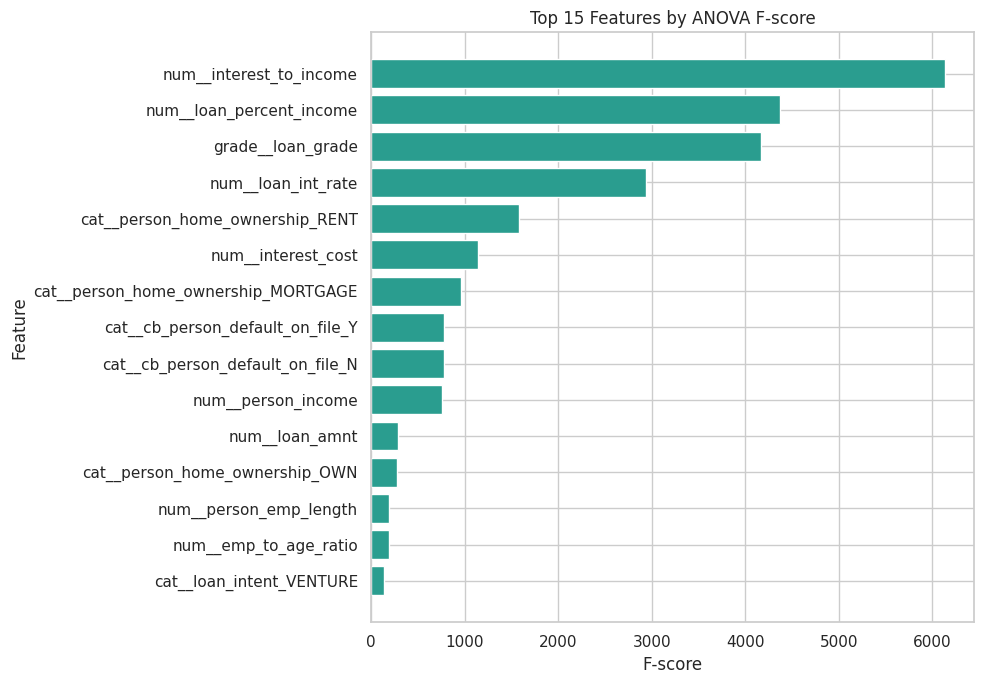

In [14]:
scores, pvals = f_classif(X_train_p, y_train)
fs = pd.DataFrame({'Feature': X_train_p.columns, 'F-score': scores.round(1), 'p-value': pvals})
fs = fs.sort_values('F-score', ascending=False).reset_index(drop=True)
display(fs.head(15))

selector = SelectFpr(score_func=f_classif, alpha=0.05)
selector.fit(X_train_p, y_train)
selected = X_train_p.columns[selector.get_support()].tolist()
removed = [c for c in X_train_p.columns if c not in selected]
print("Features before selection:", X_train_p.shape[1])
print("Features kept:", len(selected))
print("Removed (p-value >= 0.05):", removed)

top = fs.head(15).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top['Feature'], top['F-score'], color='#2a9d8f')
plt.title('Top 15 Features by ANOVA F-score')
plt.xlabel('F-score'); plt.ylabel('Feature')
plt.tight_layout()
plt.savefig(IMG + 'feature_selection_fscore.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** 25 of the 27 features were kept and 2 were removed: `age_group_36-45` and `age_group_46+`, whose relationship with default is not statistically significant (p-value above 0.05). The strongest features are `interest_to_income` (F-score 6,140), `loan_percent_income` (4,373), `loan_grade` (4,186) and `loan_int_rate` (2,939). The engineered feature `interest_to_income` is the strongest feature of all, and `interest_cost` is in the top six, which shows that feature engineering added useful information. This is a univariate test, so it only measures each feature on its own; the age information is still kept in the numerical column `person_age`. The selector is part of the final pipeline, so it is applied automatically to every new customer.

### 1.11 Verifying the Prepared Data

In [15]:
prep = Pipeline([('preprocess', preprocessor), ('select', selector)])
X_train_final = prep.transform(X_train)
X_test_final = prep.transform(X_test)

print("Raw data:", raw_rows, "rows x", raw_cols, "columns")
print("After cleaning:", df.shape[0], "rows x", df.shape[1], "columns (includes new features)")
print("Final training matrix:", X_train_final.shape, "| test matrix:", X_test_final.shape)
print("Missing values:", np.isnan(X_train_final).sum(), np.isnan(X_test_final).sum())

Raw data: 32581 rows x 12 columns
After cleaning: 32409 rows x 16 columns (includes new features)
Final training matrix: (25927, 25) | test matrix: (6482, 25)
Missing values: 0 0


**Summary of data preparation:** duplicates and impossible values were removed, four features were engineered, the data was split 80/20 with the same default rate in both parts, missing values were imputed with the median, categorical columns were encoded, numerical columns were scaled, and non-significant features were removed. Everything after the split was learned from the training data only. The data is now ready for model development.

## 2. Model Development
### 2.0 Importing Models and Creating a Reusable Training Function

In [16]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

pipelines, train_time, train_acc, test_acc = {}, {}, {}, {}

def build_pipeline(model):
    """Full pipeline: preprocessing -> feature selection -> model."""
    return Pipeline([('preprocess', clone(preprocessor)),
                     ('select', clone(selector)),
                     ('model', model)])

def train_model(name, model):
    pipe = build_pipeline(model)
    start = time.time()
    pipe.fit(X_train, y_train)
    train_time[name] = round(time.time() - start, 2)
    pipelines[name] = pipe
    train_acc[name] = pipe.score(X_train, y_train)
    test_acc[name] = pipe.score(X_test, y_test)
    print(f"{name}: trained in {train_time[name]} s | train accuracy = {train_acc[name]:.4f} | test accuracy = {test_acc[name]:.4f}")

Five classification models from different algorithm families are trained: Decision Tree, Random Forest, Gradient Boosting, Support Vector Machine and XGBoost (optional). Each model is wrapped in a scikit-learn `Pipeline` that contains the preprocessing step (imputation, encoding, scaling), the feature selector and the model. This has two advantages: the models receive raw data and the preprocessing is repeated automatically for every new customer, and there is no risk of data leakage, because every step is fitted on the training data only. `clone()` gives every model its own fresh copy of the preprocessing steps. The function also measures the training time and prints the training and testing accuracy, so that overfitting can be seen immediately.

### 2.1 Decision Tree

In [17]:
train_model('Decision Tree', DecisionTreeClassifier(random_state=42))
dt_model = pipelines['Decision Tree'].named_steps['model']
print("Tree depth:", dt_model.get_depth(), "| Number of leaves:", dt_model.get_n_leaves())

Decision Tree: trained in 0.59 s | train accuracy = 1.0000 | test accuracy = 0.8936
Tree depth: 33 | Number of leaves: 2009


A Decision Tree splits the data with yes/no questions on the features (for example "is the loan grade above C?") until it reaches a prediction. It is easy to understand and needs no scaling. This baseline tree has no depth limit, so it can grow very deep and memorize the training data (overfitting). It is included as the simple baseline against which the ensemble models are compared, and its depth can be controlled by hyperparameter tuning in Part 3.

**Observation:** The Decision Tree reached 100% training accuracy but only 89.36% testing accuracy. Its depth is 33 with 2,009 leaves, so it has memorized the training data (overfitting).

### 2.2 Random Forest

In [18]:
train_model('Random Forest', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))

Random Forest: trained in 9.91 s | train accuracy = 1.0000 | test accuracy = 0.9352


A Random Forest builds many decision trees (here 200). Each tree is trained on a random sample of the rows and a random subset of the features, and the final prediction is the vote of all trees. Because the errors of individual trees partly cancel each other, the forest is more accurate and less prone to overfitting than one tree. It handles non-linear patterns and mixed features well and provides feature importance. It needs more training time and is harder to interpret than one tree.

**Observation:** The Random Forest also shows 100% training accuracy, but its testing accuracy is much higher than the single tree (93.52% against 89.36%), which shows the benefit of combining many trees. It took 14.71 seconds to train.

### 2.3 Gradient Boosting

In [19]:
train_model('Gradient Boosting', GradientBoostingClassifier(random_state=42))

Gradient Boosting: trained in 6.14 s | train accuracy = 0.9310 | test accuracy = 0.9310


Gradient Boosting builds shallow trees one after another, and each new tree tries to correct the errors made by the previous trees. This step-by-step improvement often gives very accurate models on tabular data. Unlike Random Forest, the trees are not independent, so training cannot be parallelized and is slower. The learning rate, the number of trees and the tree depth are important hyperparameters.

**Observation:** Gradient Boosting has identical training and testing accuracy (93.10%), so it does not overfit.

### 2.4 Support Vector Machine (SVM)

In [20]:
train_model('SVM', SVC(kernel='rbf', random_state=42))

SVM: trained in 17.02 s | train accuracy = 0.9156 | test accuracy = 0.9101


A Support Vector Machine looks for the boundary that separates the two classes with the largest possible margin. With the RBF kernel it can create curved (non-linear) boundaries. SVM depends on distances, so it needs scaled features, which the pipeline provides. Its training time grows quickly with the number of rows (about 26,000 here), so it is expected to be the slowest model, and it is also the hardest to interpret. Probability estimates were not enabled because they would make training several times slower; the ROC-AUC is calculated from the decision function instead.

**Observation:** SVM was the slowest model (18.67 seconds) and reached a testing accuracy of 91.01%, the lowest of the ensemble-style models.

### 2.5 XGBoost

In [21]:
train_model('XGBoost', XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4,
                                     eval_metric='logloss', random_state=42, n_jobs=-1))

XGBoost: trained in 0.7 s | train accuracy = 0.9387 | test accuracy = 0.9397


XGBoost is an optimized and regularized implementation of gradient boosting. It builds trees one after another like Gradient Boosting, but it is much faster, uses regularization to reduce overfitting and handles large tables efficiently. A small `max_depth` of 4 and a learning rate of 0.1 keep the trees simple. It needs no scaling, but it has many hyperparameters to tune.

**Observation:** XGBoost reached the highest testing accuracy (93.97%) in only 2.24 seconds. Its testing accuracy is even slightly higher than its training accuracy (93.87%), so there is no sign of overfitting.

### 2.6 Evaluating the Models on the Test Set

In [22]:
def get_scores(pipe, X):
    return pipe.predict_proba(X)[:, 1] if hasattr(pipe, 'predict_proba') else pipe.decision_function(X)

rows, preds = [], {}
for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    preds[name] = y_pred
    rows.append({'Model': name,
                 'Train Time (s)': train_time[name],
                 'Train Accuracy': train_acc[name],
                 'Accuracy': accuracy_score(y_test, y_pred),
                 'Precision': precision_score(y_test, y_pred),
                 'Recall': recall_score(y_test, y_pred),
                 'F1 Score': f1_score(y_test, y_pred),
                 'ROC-AUC': roc_auc_score(y_test, get_scores(pipe, X_test))})

results_df = pd.DataFrame(rows).round(4).set_index('Model')
results_df['Gap (Train - Test Acc.)'] = (results_df['Train Accuracy'] - results_df['Accuracy']).round(4)
display(results_df.sort_values('F1 Score', ascending=False))
results_df.to_csv(IMG + 'baseline_results.csv')

,Train Time (s),Train Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Gap (Train - Test Acc.)
Model,,,,,,,,
XGBoost,0.70,0.9387,0.9397,0.9849,0.7355,0.8421,0.9499,-0.0010
Random Forest,9.91,1.0000,0.9352,0.9699,0.7264,0.8306,0.9367,0.0648
Gradient Boosting,6.14,0.9310,0.9310,0.9500,0.7228,0.8210,0.9325,0.0000
Decision Tree,0.59,1.0000,0.8936,0.7398,0.7920,0.7650,0.8570,0.1064
SVM,17.02,0.9156,0.9101,0.9196,0.6453,0.7584,0.8937,0.0055


All models were evaluated on the test set (6,482 loans) that they have never seen. Accuracy, precision, recall, F1 score and ROC-AUC were calculated, and the gap between training and testing accuracy shows overfitting. The positive class is "default" (loan_status = 1). Precision tells how many of the loans predicted to default really defaulted, and recall tells how many of the real defaults the model found. For a lender, missing a default (low recall) is usually costlier than rejecting a good loan, so recall and F1 are as important as accuracy.

**Observation:**
- XGBoost is the best model on accuracy (93.97%), precision (98.49%), F1 score (0.8421) and ROC-AUC (0.9499). Random Forest (F1 0.8306) and Gradient Boosting (F1 0.8210) follow.
- The Decision Tree has the highest recall (79.20%), but its precision is only 73.98%: it finds more defaults but also flags many good loans by mistake.
- SVM has the lowest recall (64.53%) and the lowest F1 score (0.7584), and it is also the slowest model.
- The ensemble models have very high precision (95% to 98%) but a recall of only 65% to 74%, which means they miss a quarter or more of the real defaults. The baseline accuracy of always predicting "no default" is 78.18%, so all models are clearly better than guessing.
- Random Forest and the Decision Tree overfit (gaps of 6.48 and 10.64 points), while XGBoost, Gradient Boosting and SVM generalize well.

### 2.7 Confusion Matrices and Metrics Comparison

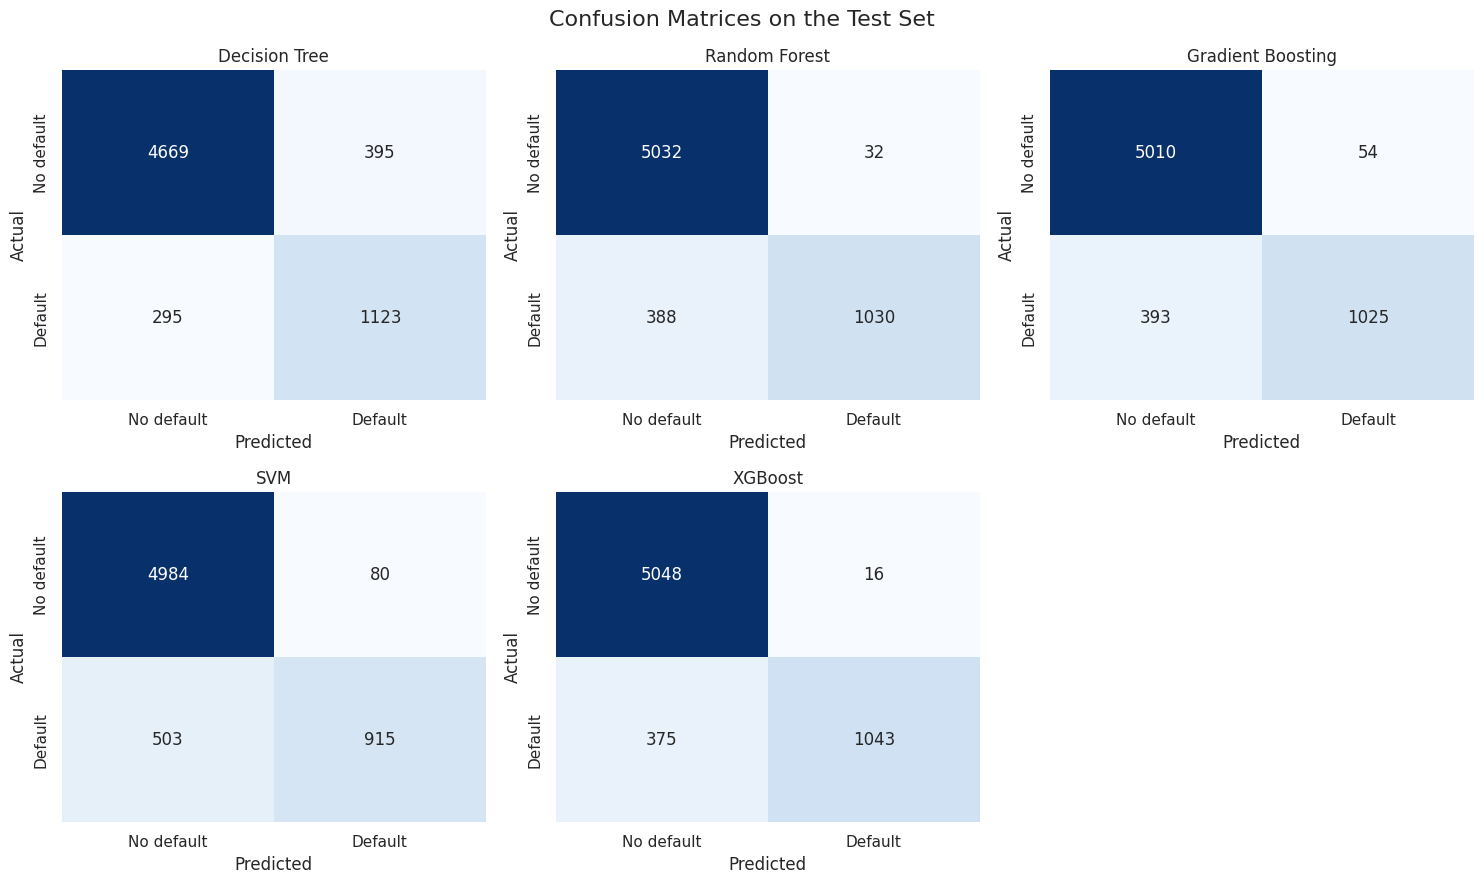

,TN,FP,FN,TP
Model,,,,
Decision Tree,4669,395,295,1123
Random Forest,5032,32,388,1030
Gradient Boosting,5010,54,393,1025
SVM,4984,80,503,915
XGBoost,5048,16,375,1043


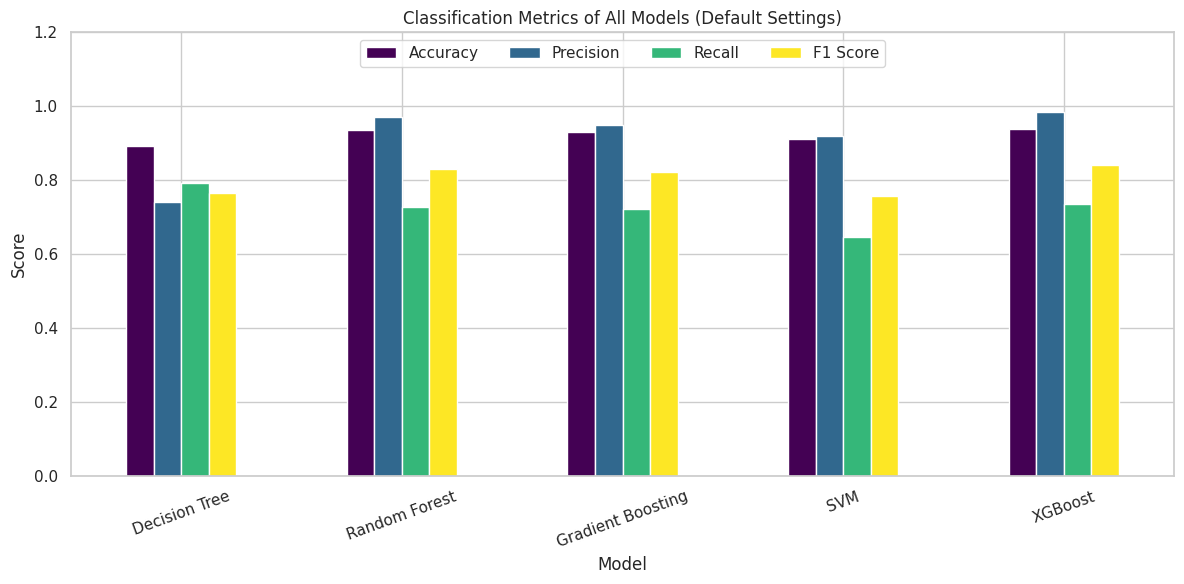

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No default', 'Default'], yticklabels=['No default', 'Default'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
axes.ravel()[-1].axis('off')
plt.suptitle('Confusion Matrices on the Test Set', fontsize=16)
plt.tight_layout()
plt.savefig(IMG + 'confusion_matrices_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

cm_rows = []
for name, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    cm_rows.append({'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
display(pd.DataFrame(cm_rows).set_index('Model'))

results_df[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Classification Metrics of All Models (Default Settings)')
plt.xlabel('Model'); plt.ylabel('Score'); plt.ylim(0, 1.05)
plt.ylim(0, 1.2)
plt.xticks(rotation=20); plt.legend(loc='upper center', ncol=4)
plt.tight_layout()
plt.savefig(IMG + 'metrics_comparison_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The test set contains 1,418 real defaults. XGBoost finds 1,043 of them and misses 375, with only 16 false alarms. The Decision Tree finds the most defaults (1,123) but raises 395 false alarms, and SVM misses the most (503). For a lender, a missed default (false negative) is usually more expensive than a rejected good loan, so recall needs to be improved. This is the main goal of the optimization in Part 3.

## 3. Model Optimization
### 3.1 Cross-Validation of the Models

Decision Tree done in 4.5 s
Random Forest done in 36.6 s
Gradient Boosting done in 23.2 s
SVM done in 81.7 s
XGBoost done in 3.0 s


,CV Accuracy,CV Recall,CV F1,CV F1 Std,CV ROC-AUC
Model,,,,,
XGBoost,0.9352,0.7233,0.8299,0.0040,0.9431
Random Forest,0.9327,0.7168,0.8233,0.0050,0.9305
Gradient Boosting,0.9297,0.7145,0.8164,0.0043,0.9287
SVM,0.9094,0.6423,0.7562,0.0064,0.8911
Decision Tree,0.8905,0.7677,0.7542,0.0097,0.8463


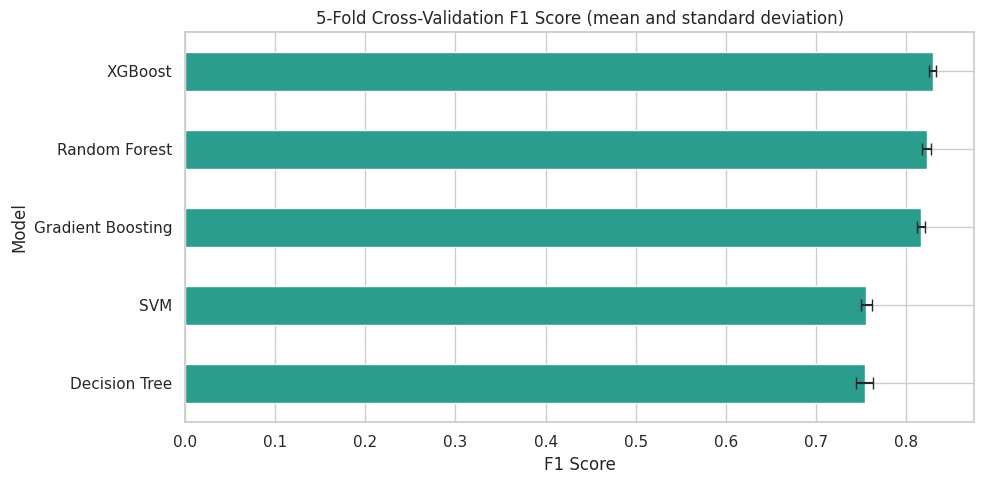

In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.inspection import permutation_importance

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, pipe in pipelines.items():
    start = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv5, n_jobs=-1,
                         scoring=['accuracy', 'recall', 'f1', 'roc_auc'])
    cv_rows.append({'Model': name,
                    'CV Accuracy': res['test_accuracy'].mean(),
                    'CV Recall': res['test_recall'].mean(),
                    'CV F1': res['test_f1'].mean(),
                    'CV F1 Std': res['test_f1'].std(),
                    'CV ROC-AUC': res['test_roc_auc'].mean()})
    print(f"{name} done in {round(time.time() - start, 1)} s")

cv_df = pd.DataFrame(cv_rows).round(4).set_index('Model')
display(cv_df.sort_values('CV F1', ascending=False))
cv_df.to_csv(IMG + 'cross_validation_results.csv')

cv_df['CV F1'].sort_values().plot(kind='barh', xerr=cv_df['CV F1 Std'].reindex(cv_df['CV F1'].sort_values().index),
                                  color='#2a9d8f', figsize=(10, 5), capsize=4)
plt.title('5-Fold Cross-Validation F1 Score (mean and standard deviation)')
plt.xlabel('F1 Score'); plt.ylabel('Model')
plt.tight_layout()
plt.savefig(IMG + 'cross_validation_f1.png', dpi=300, bbox_inches='tight')
plt.show()

A single train-test split can be lucky or unlucky. In 5-fold stratified cross-validation, the training data is divided into 5 parts; each part is used once for validation while the model is trained on the other 4. The average and the standard deviation of the scores give a more reliable estimate of how well a model generalizes. The whole pipeline (imputation, scaling, encoding, feature selection and model) is refitted inside every fold, so there is no data leakage. A small standard deviation means that the model is stable.

**Observation:**
- XGBoost has the best cross-validated F1 score (0.8299), followed by Random Forest (0.8233) and Gradient Boosting (0.8164). SVM (0.7562) and the Decision Tree (0.7542) are nearly tied at the bottom. The ranking agrees with the results on the single test split in Part 2.
- The standard deviation of the F1 score is small for all models (0.0040 to 0.0097), so the results are stable and do not depend on one lucky split. XGBoost is the most stable (0.0040), the Decision Tree the least (0.0097).
- The Decision Tree has the highest cross-validated recall (76.77%) but the lowest F1 score, because its precision is low.
- SVM (89.9 s) and Random Forest (81.9 s) were the slowest to cross-validate, while XGBoost needed only 3.5 s.

### 3.2 Hyperparameter Tuning

In [25]:
spw = round((y_train == 0).sum() / (y_train == 1).sum(), 2)   # ratio of non-defaults to defaults
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print("Ratio of non-defaults to defaults (for XGBoost):", spw)

search_plan = {
    'Decision Tree': GridSearchCV(
        build_pipeline(DecisionTreeClassifier(random_state=42)),
        {'model__max_depth': [4, 6, 8, 12], 'model__min_samples_leaf': [5, 20, 50],
         'model__class_weight': [None, 'balanced']},
        cv=cv3, scoring='f1', n_jobs=-1),
    'Random Forest': RandomizedSearchCV(
        build_pipeline(RandomForestClassifier(random_state=42)),
        {'model__n_estimators': [200, 300], 'model__max_depth': [10, 15, None],
         'model__min_samples_leaf': [1, 2, 5], 'model__max_features': ['sqrt', 0.5],
         'model__class_weight': [None, 'balanced']},
        n_iter=8, cv=cv3, scoring='f1', random_state=42, n_jobs=-1),
    'Gradient Boosting': RandomizedSearchCV(
        build_pipeline(GradientBoostingClassifier(random_state=42)),
        {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.05, 0.1, 0.2],
         'model__max_depth': [3, 4, 5], 'model__subsample': [0.8, 1.0],
         'model__min_samples_leaf': [1, 5]},
        n_iter=8, cv=cv3, scoring='f1', random_state=42, n_jobs=-1),
    'XGBoost': RandomizedSearchCV(
        build_pipeline(XGBClassifier(eval_metric='logloss', random_state=42)),
        {'model__n_estimators': [200, 300, 400], 'model__max_depth': [3, 4, 5, 6],
         'model__learning_rate': [0.03, 0.05, 0.1], 'model__subsample': [0.7, 0.85, 1.0],
         'model__colsample_bytree': [0.7, 0.85, 1.0], 'model__scale_pos_weight': [1, spw]},
        n_iter=15, cv=cv3, scoring='f1', random_state=42, n_jobs=-1)
}
print("Search plan ready for:", list(search_plan.keys()))

Ratio of non-defaults to defaults (for XGBoost): 3.57
Search plan ready for: ['Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']


Hyperparameters are settings chosen before training (for example the tree depth or the learning rate) that strongly influence a model. Four models are tuned:
- **GridSearchCV** (Decision Tree) tries every combination of a small grid.
- **RandomizedSearchCV** (Random Forest, Gradient Boosting, XGBoost) tries a fixed number of random combinations from a large space, which is much faster than testing all of them.

Every combination is evaluated with 3-fold stratified cross-validation on the training data only, using the **F1 score** for selection, because the first results showed a low recall and F1 balances precision and recall. The test set is not touched during tuning. `class_weight` and `scale_pos_weight` were included so that the models can pay more attention to the minority class (defaults). SVM was not tuned because it was the slowest and the weakest model.

### 3.3 Running the Searches

In [26]:
tuned, tune_info = {}, {}
for name, search in search_plan.items():
    start = time.time()
    search.fit(X_train, y_train)
    secs = round(time.time() - start, 1)
    tuned[name] = search.best_estimator_
    tune_info[name] = {'best_cv_f1': round(search.best_score_, 4), 'search_time_s': secs,
                       'best_params': {k.replace('model__', ''): v for k, v in search.best_params_.items()}}
    print(f"{name} | best CV F1 = {search.best_score_:.4f} | search time = {secs} s")
    print("   Best parameters:", tune_info[name]['best_params'])

Decision Tree | best CV F1 = 0.8143 | search time = 15.6 s
   Best parameters: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 5}
Random Forest | best CV F1 = 0.8238 | search time = 178.7 s
   Best parameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15, 'class_weight': None}
Gradient Boosting | best CV F1 = 0.8311 | search time = 228.1 s
   Best parameters: {'subsample': 0.8, 'n_estimators': 200, 'min_samples_leaf': 1, 'max_depth': 5, 'learning_rate': 0.1}
XGBoost | best CV F1 = 0.8314 | search time = 44.1 s
   Best parameters: {'subsample': 0.85, 'scale_pos_weight': 1, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


**Observation:**
- The best cross-validation F1 scores after tuning are XGBoost 0.8314, Gradient Boosting 0.8311, Random Forest 0.8238 and Decision Tree 0.8143. XGBoost and Gradient Boosting are practically tied.
- The searches took 227.0 s (Gradient Boosting), 188.4 s (Random Forest), 44.9 s (XGBoost) and 19.9 s (Decision Tree).
- The Decision Tree chose a maximum depth of 8 (instead of 33) and at least 5 samples per leaf, which removes its overfitting. Gradient Boosting and XGBoost both chose 200 trees with a depth of 5 and a learning rate of 0.1, together with row sampling (0.8 and 0.85). The Random Forest chose a depth of 15 and half of the features per split.
- All four searches chose no class weighting (`class_weight=None`, `scale_pos_weight=1`). On this dataset the precision is already very high (95% to 98%), so giving more weight to defaults would raise recall but lower precision more than it helps, and the F1 score would not improve.

### 3.4 Comparing the Models Before and After Tuning

,Accuracy Before,Accuracy After,Precision Before,Precision After,Recall Before,Recall After,F1 Before,F1 After,AUC Before,AUC After,F1 Change,Recall Change
Model,,,,,,,,,,,,
Gradient Boosting,0.9310,0.9405,0.9500,0.9751,0.7228,0.7468,0.8210,0.8458,0.9325,0.9514,0.0248,0.0240
XGBoost,0.9397,0.9389,0.9849,0.9758,0.7355,0.7391,0.8421,0.8411,0.9499,0.9511,-0.0010,0.0036
Random Forest,0.9352,0.9371,0.9699,0.9819,0.7264,0.7257,0.8306,0.8345,0.9367,0.9392,0.0039,-0.0007
Decision Tree,0.8936,0.9347,0.7398,0.9752,0.7920,0.7200,0.7650,0.8284,0.8570,0.9183,0.0634,-0.0720


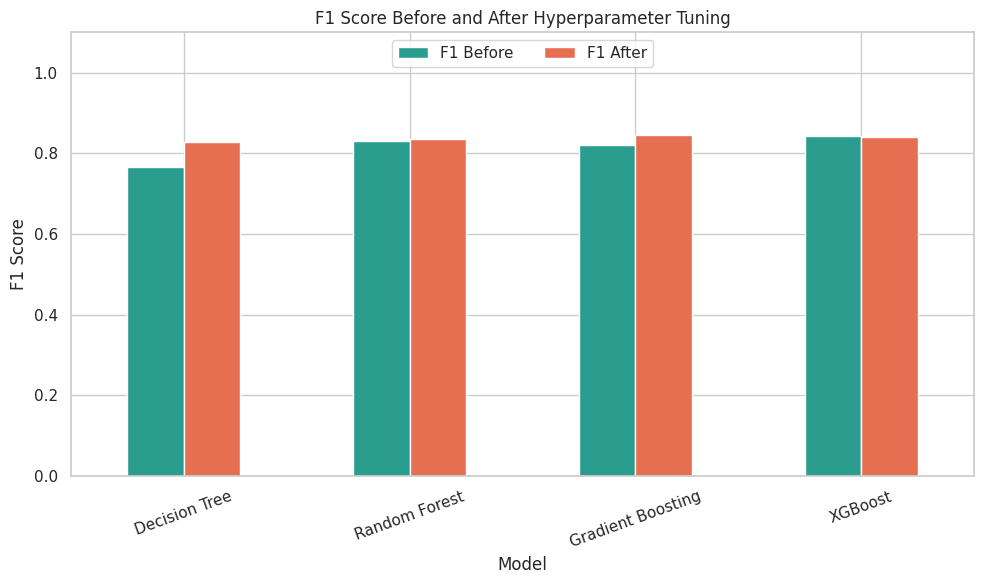

In [27]:
rows = []
for name, pipe in tuned.items():
    y_pred = pipe.predict(X_test)
    b = results_df.loc[name]
    rows.append({'Model': name,
                 'Accuracy Before': b['Accuracy'], 'Accuracy After': accuracy_score(y_test, y_pred),
                 'Precision Before': b['Precision'], 'Precision After': precision_score(y_test, y_pred),
                 'Recall Before': b['Recall'], 'Recall After': recall_score(y_test, y_pred),
                 'F1 Before': b['F1 Score'], 'F1 After': f1_score(y_test, y_pred),
                 'AUC Before': b['ROC-AUC'], 'AUC After': roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])})

tune_df = pd.DataFrame(rows).set_index('Model').round(4)
tune_df['F1 Change'] = (tune_df['F1 After'] - tune_df['F1 Before']).round(4)
tune_df['Recall Change'] = (tune_df['Recall After'] - tune_df['Recall Before']).round(4)
display(tune_df.sort_values('F1 After', ascending=False))
tune_df.to_csv(IMG + 'tuning_comparison.csv')

tune_df[['F1 Before', 'F1 After']].plot(kind='bar', figsize=(10, 6), color=['#2a9d8f', '#e76f51'])
plt.title('F1 Score Before and After Hyperparameter Tuning')
plt.xlabel('Model'); plt.ylabel('F1 Score'); plt.ylim(0, 1.1)
plt.xticks(rotation=20); plt.legend(loc='upper center', ncol=2)
plt.tight_layout()
plt.savefig(IMG + 'tuning_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- Tuning improved the F1 score of three models: Decision Tree +0.0634 (0.7650 to 0.8284), Gradient Boosting +0.0248 (0.8210 to 0.8458) and Random Forest +0.0039 (0.8306 to 0.8345). XGBoost stayed practically the same (0.8421 to 0.8411), because its default settings were already well chosen; this difference is smaller than the variation seen in cross-validation.
- The Decision Tree benefited most. Limiting its depth removed the overfitting: accuracy rose from 89.36% to 93.47% and precision from 73.98% to 97.52%, while recall fell from 79.20% to 72.00%.
- **Gradient Boosting is the best tuned model**: F1 score 0.8458, accuracy 94.05%, precision 97.51%, recall 74.68% and ROC-AUC 0.9514. XGBoost is almost identical (F1 0.8411, ROC-AUC 0.9511) and was five times faster to tune.
- Recall stays between 72% and 75% for all tuned models, so about a quarter of the real defaults are still missed. Tuning for the F1 score improved precision and overall quality, but it did not solve the recall problem; this is investigated with the decision threshold in Section 3.6.

### 3.5 Feature Importance Analysis

Best tuned model: Gradient Boosting


,0
num__loan_percent_income,0.2507
grade__loan_grade,0.2042
cat__person_home_ownership_RENT,0.1457
num__person_income,0.1280
num__person_emp_length,0.0405
cat__loan_intent_DEBTCONSOLIDATION,0.0399
num__interest_to_income,0.0370
cat__loan_intent_MEDICAL,0.0361
num__loan_int_rate,0.0184
cat__person_home_ownership_OWN,0.0181


,0
loan_grade,0.2280
loan_percent_income,0.2115
person_home_ownership,0.1693
loan_intent,0.1282
person_income,0.1207
interest_to_income,0.0883
loan_amnt,0.0517
person_emp_length,0.0410
person_age,0.0396
loan_int_rate,0.0190


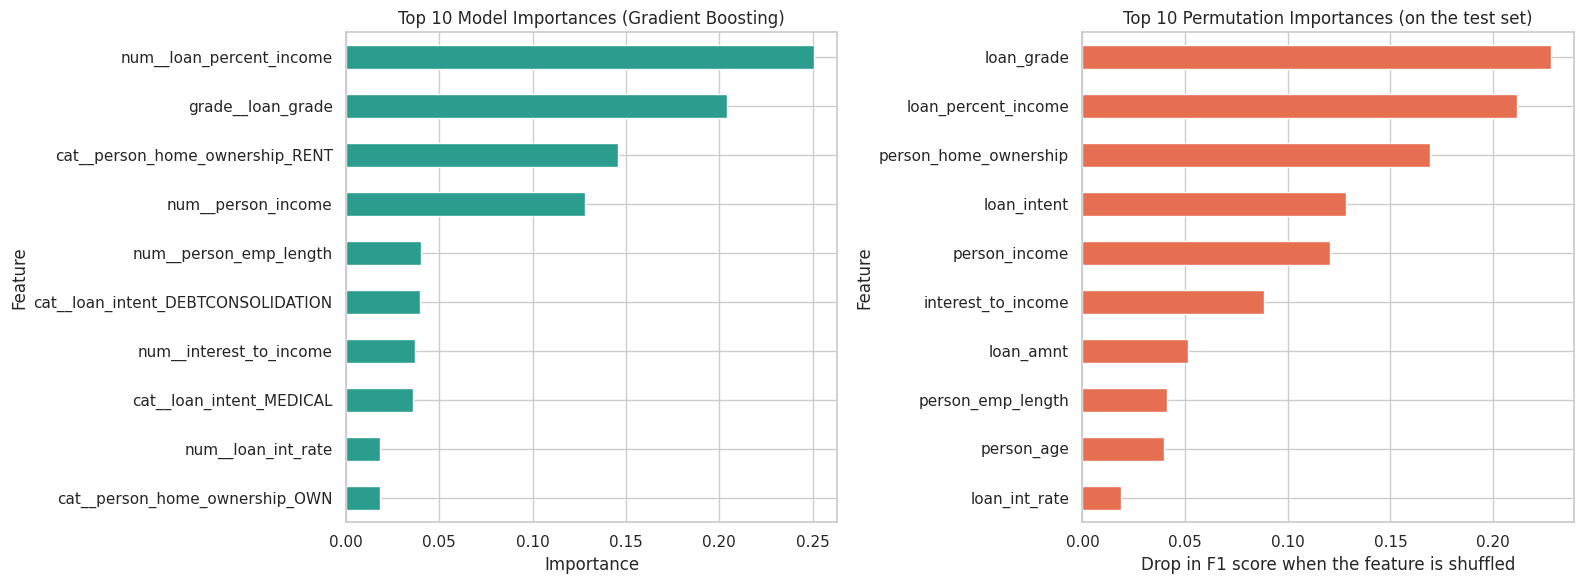

In [28]:
best_name = tune_df['F1 After'].idxmax()
best_pipe = tuned[best_name]
print("Best tuned model:", best_name)

feat_names = best_pipe[:-1].get_feature_names_out()
imp = pd.Series(best_pipe.named_steps['model'].feature_importances_, index=feat_names)
imp = imp.sort_values(ascending=False)
display(imp.head(10).round(4))

perm = permutation_importance(best_pipe, X_test, y_test, scoring='f1', n_repeats=5,
                              random_state=42, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(perm_s.head(10).round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
imp.head(10)[::-1].plot(kind='barh', color='#2a9d8f', ax=ax[0])
ax[0].set_title(f'Top 10 Model Importances ({best_name})')
ax[0].set_xlabel('Importance'); ax[0].set_ylabel('Feature')
perm_s.head(10)[::-1].plot(kind='barh', color='#e76f51', ax=ax[1])
ax[1].set_title('Top 10 Permutation Importances (on the test set)')
ax[1].set_xlabel('Drop in F1 score when the feature is shuffled'); ax[1].set_ylabel('Feature')
plt.tight_layout()
plt.savefig(IMG + 'feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

Two kinds of feature importance are shown for the best tuned model:
- **Model importance** (left): how much each feature helped the trees to reduce impurity during training. It is calculated on the encoded features, so a categorical column appears as several 0/1 columns.
- **Permutation importance** (right): each original column of the test set is shuffled in turn, and the drop in F1 score is measured. A large drop means that the model depends strongly on this column. It is calculated on the raw columns, so it is easier to interpret, and it works on data the model has not seen.

**Observation:**
- For the best tuned model (Gradient Boosting) the permutation importance shows that `loan_grade` is the most important column (the F1 score drops by 0.2280 when it is shuffled), followed by `loan_percent_income` (0.2115), `person_home_ownership` (0.1693), `loan_intent` (0.1282) and `person_income` (0.1207).
- The model importance (left chart) gives a similar picture: `loan_percent_income`, `loan_grade`, renting a home and `person_income` are at the top.
- The engineered feature `interest_to_income` is in the top six of the permutation importance (0.0883), ahead of `loan_amnt` (0.0517), `person_emp_length` (0.0410) and `person_age` (0.0396). This confirms that feature engineering added useful information.
- `loan_int_rate` has a low permutation importance (0.0190), although it is closely related to the loan grade. When two columns carry almost the same information, shuffling one of them costs little because the model can use the other one.
- Overall, a loan is judged mainly by its risk grade, how large the loan is compared with the income and the borrower's housing situation, which agrees with common credit-risk practice.

### 3.6 Decision Threshold Analysis (Precision-Recall Trade-off)

,Val Precision,Val Recall,Val F1,Test Precision,Test Recall,Test F1
Threshold,,,,,,
0.50,0.9572,0.7344,0.8311,0.9751,0.7468,0.8458
0.40,0.9264,0.7529,0.8307,0.9466,0.7630,0.8450
0.35,0.9010,0.7644,0.8271,0.9198,0.7687,0.8375
0.30,0.8705,0.7810,0.8233,0.8868,0.7842,0.8323
0.25,0.8274,0.7963,0.8115,0.8485,0.8096,0.8286
0.20,0.7694,0.8155,0.7918,0.7779,0.8272,0.8018


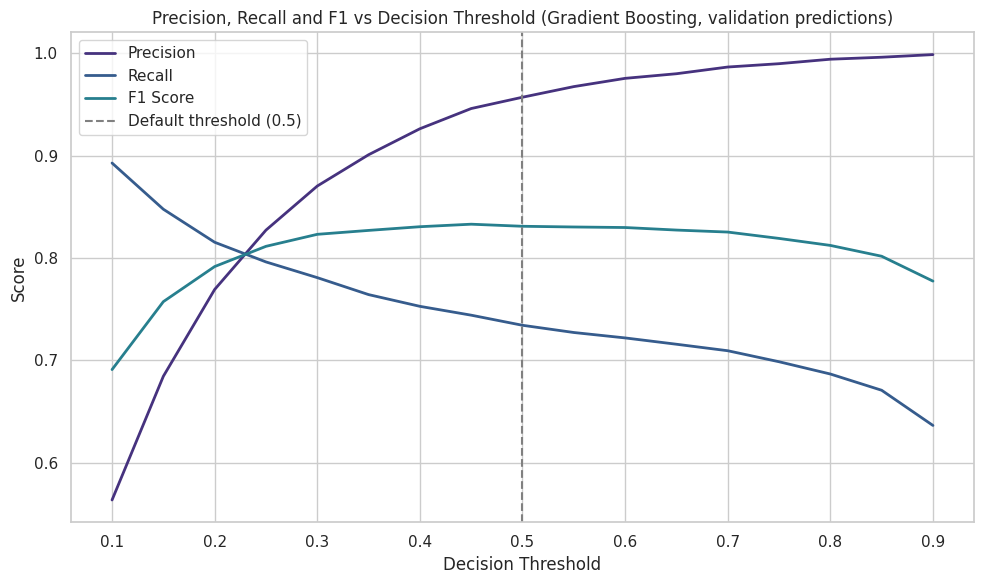

In [29]:
from sklearn.model_selection import cross_val_predict

val_prob = cross_val_predict(best_pipe, X_train, y_train, cv=cv3,
                             method='predict_proba', n_jobs=-1)[:, 1]
test_prob = best_pipe.predict_proba(X_test)[:, 1]

rows = []
for t in [0.5, 0.4, 0.35, 0.3, 0.25, 0.2]:
    rows.append({'Threshold': t,
                 'Val Precision': precision_score(y_train, val_prob >= t),
                 'Val Recall': recall_score(y_train, val_prob >= t),
                 'Val F1': f1_score(y_train, val_prob >= t),
                 'Test Precision': precision_score(y_test, test_prob >= t),
                 'Test Recall': recall_score(y_test, test_prob >= t),
                 'Test F1': f1_score(y_test, test_prob >= t)})
thr_df = pd.DataFrame(rows).set_index('Threshold').round(4)
display(thr_df)
thr_df.to_csv(IMG + 'threshold_analysis.csv')

grid = np.arange(0.1, 0.91, 0.05)
plt.figure(figsize=(10, 6))
plt.plot(grid, [precision_score(y_train, val_prob >= t, zero_division=0) for t in grid], label='Precision', linewidth=2)
plt.plot(grid, [recall_score(y_train, val_prob >= t) for t in grid], label='Recall', linewidth=2)
plt.plot(grid, [f1_score(y_train, val_prob >= t) for t in grid], label='F1 Score', linewidth=2)
plt.axvline(0.5, color='grey', linestyle='--', label='Default threshold (0.5)')
plt.title(f'Precision, Recall and F1 vs Decision Threshold ({best_name}, validation predictions)')
plt.xlabel('Decision Threshold'); plt.ylabel('Score')
plt.legend(); plt.tight_layout()
plt.savefig(IMG + 'threshold_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

The model predicts a probability of default, and by default a loan is flagged when this probability is at least 0.5. A lower threshold flags more loans: recall rises (more real defaults are found) but precision falls (more good loans are flagged by mistake). The threshold was evaluated on cross-validated predictions of the training data and then checked on the test set, so the test set was not used to choose it.

**Observation:**
- At the default threshold of 0.5 the best model has a validation precision of 95.72% and a recall of 73.44% (F1 0.8311). The F1 curve is almost flat between thresholds of about 0.35 and 0.7 (around 0.83), so 0.5 is already close to the best possible F1 score.
- Lowering the threshold increases recall and lowers precision. On the test set, a threshold of 0.4 raises recall from 74.68% to 76.30% while precision falls from 97.51% to 94.66% (F1 0.8450). A threshold of 0.3 gives a recall of 78.42% and a precision of 88.68% (F1 0.8323), and a threshold of 0.2 gives a recall of 82.72% with a precision of 77.79% (F1 0.8018).
- On the validation curve precision and recall cross at a threshold of about 0.22, where both are about 0.80.
- The best threshold depends on the cost of the two errors. If missing a default is much more expensive than rejecting a good loan, a lower threshold (0.3 to 0.4) is preferable; if both errors cost about the same, 0.5 is a good choice. Because 0.5 gives practically the best F1 score (the difference to 0.4 is below 0.001), it is used as the final threshold of the saved model, and the Streamlit interface will let the user change it.

## 4. Saving the Best Model
### 4.1 Saving the Pipeline with Joblib and Pickle

In [30]:
import joblib
import pickle
import json
import sklearn

MODELS = '/content/drive/MyDrive/Task_03_AI_ML/models/'
os.makedirs(MODELS, exist_ok=True)

final_model = tuned[best_name]     # the best tuned pipeline (preprocessing + selection + model)

joblib_path = MODELS + 'credit_risk_pipeline.joblib'
pickle_path = MODELS + 'credit_risk_pipeline.pkl'

joblib.dump(final_model, joblib_path)
with open(pickle_path, 'wb') as f:
    pickle.dump(final_model, f)

for p in [joblib_path, pickle_path]:
    print(os.path.basename(p), "->", round(os.path.getsize(p) / 1024, 1), "KB")
print("scikit-learn version:", sklearn.__version__)

credit_risk_pipeline.joblib -> 858.6 KB
credit_risk_pipeline.pkl -> 869.6 KB
scikit-learn version: 1.6.1


The best tuned model was saved in two formats. **Joblib** is efficient for objects that contain large NumPy arrays, which is typical for scikit-learn models. **Pickle** is the standard Python serialization format. The saved object is the complete pipeline (imputation, scaling, encoding, feature selection and the model), so it accepts raw customer data and needs no separate preprocessing code. The scikit-learn version is printed because a saved model should be loaded with the same version.

**Observation:** The best tuned model (Gradient Boosting) was saved as `credit_risk_pipeline.joblib` (858.6 KB) and `credit_risk_pipeline.pkl` (869.6 KB). Both files are small, so they are easy to share and deploy. They were created with scikit-learn 1.6.1, and the same version should be used when loading them.

### 4.2 Loading the Saved Models and Verifying Them

In [31]:
model_joblib = joblib.load(joblib_path)
with open(pickle_path, 'rb') as f:
    model_pickle = pickle.load(f)

original = final_model.predict_proba(X_test)[:, 1]
print("Joblib model gives identical predictions:", np.allclose(original, model_joblib.predict_proba(X_test)[:, 1]))
print("Pickle model gives identical predictions:", np.allclose(original, model_pickle.predict_proba(X_test)[:, 1]))

pred_loaded = model_joblib.predict(X_test)
print("Loaded model - Accuracy:", round(accuracy_score(y_test, pred_loaded), 4),
      "| Recall:", round(recall_score(y_test, pred_loaded), 4),
      "| F1:", round(f1_score(y_test, pred_loaded), 4))

Joblib model gives identical predictions: True
Pickle model gives identical predictions: True
Loaded model - Accuracy: 0.9405 | Recall: 0.7468 | F1: 0.8458


Both files were loaded again and used to predict the test set. The predictions are identical to those of the original model, and the metrics are the same, so the saving worked correctly and the models can be reused without retraining.

**Observation:** Both the Joblib and the Pickle model give predictions identical to the original model (`True` for both checks), and the loaded model reproduces the test metrics exactly (accuracy 0.9405, recall 0.7468, F1 0.8458). The saved models can therefore be reused without retraining.

### 4.3 Predicting New Customers with the Saved Pipeline

In [32]:
def add_engineered_features(data):
    """Same feature engineering as in Section 1.7, reusable for new data."""
    data = data.copy()
    data['emp_to_age_ratio'] = (data['person_emp_length'] / data['person_age']).round(4)
    data['interest_cost'] = (data['loan_amnt'] * data['loan_int_rate'] / 100).round(2)
    data['interest_to_income'] = (data['interest_cost'] / data['person_income']).round(4)
    data['age_group'] = pd.cut(data['person_age'], bins=[0, 25, 35, 45, 100],
                               labels=['up to 25', '26-35', '36-45', '46+']).astype(str)
    return data

FINAL_THRESHOLD = 0.5      # change this after Section 3.6 if another threshold is chosen

new_customers = pd.DataFrame([
    {'person_age': 35, 'person_income': 90000, 'person_home_ownership': 'MORTGAGE', 'person_emp_length': 10,
     'loan_intent': 'EDUCATION', 'loan_grade': 'A', 'loan_amnt': 5000, 'loan_int_rate': 7.5,
     'loan_percent_income': 0.06, 'cb_person_default_on_file': 'N', 'cb_person_cred_hist_length': 10},
    {'person_age': 22, 'person_income': 25000, 'person_home_ownership': 'RENT', 'person_emp_length': 1,
     'loan_intent': 'MEDICAL', 'loan_grade': 'E', 'loan_amnt': 12000, 'loan_int_rate': 17.5,
     'loan_percent_income': 0.48, 'cb_person_default_on_file': 'Y', 'cb_person_cred_hist_length': 2}
])

new_X = add_engineered_features(new_customers)
prob = model_joblib.predict_proba(new_X)[:, 1]
new_customers['default_probability'] = prob.round(4)
new_customers['decision'] = np.where(prob >= FINAL_THRESHOLD, 'High risk (default likely)', 'Low risk')
display(new_customers[['person_income', 'loan_grade', 'loan_amnt', 'loan_percent_income',
                       'default_probability', 'decision']])

,person_income,loan_grade,loan_amnt,loan_percent_income,default_probability,decision
0,90000,A,5000,0.06,0.0133,Low risk
1,25000,E,12000,0.48,0.9985,High risk (default likely)


Two example applicants were created as raw data. The reusable function `add_engineered_features` calculates the four engineered features, and the loaded pipeline then does everything else (imputation, encoding, scaling, selection and prediction). The first applicant (grade A, small loan, high income) should get a low default probability and the second (grade E, large loan, low income, previous default) a high one. The same two steps will be used by the Streamlit interface.

**Observation:** The first applicant (grade A, a 5,000 loan that is 6% of an income of 90,000, no previous default) gets a default probability of only 1.33% and is classified as low risk. The second applicant (grade E, a 12,000 loan that is 48% of an income of 25,000, with a previous default) gets a probability of 99.85% and is classified as high risk. The predictions agree with common sense, and the saved pipeline works on raw input data without any separate preprocessing.

### 4.4 Saving the Model Information

In [33]:
import xgboost

final_pred = final_model.predict(X_test)
metadata = {
    'model': best_name,
    'best_params': tune_info[best_name]['best_params'],
    'threshold': FINAL_THRESHOLD,
    'test_metrics': {'accuracy': round(accuracy_score(y_test, final_pred), 4),
                     'precision': round(precision_score(y_test, final_pred), 4),
                     'recall': round(recall_score(y_test, final_pred), 4),
                     'f1': round(f1_score(y_test, final_pred), 4),
                     'roc_auc': round(roc_auc_score(y_test, final_model.predict_proba(X_test)[:, 1]), 4)},
    'training_rows': int(len(X_train)),
    'raw_input_columns': ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length',
                          'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate',
                          'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length'],
    'sklearn_version': sklearn.__version__,
    'xgboost_version': xgboost.__version__
}
with open(MODELS + 'model_info.json', 'w') as f:
    json.dump(metadata, f, indent=2, default=str)
print(json.dumps(metadata, indent=2, default=str))

{
  "model": "Gradient Boosting",
  "best_params": {
    "subsample": 0.8,
    "n_estimators": 200,
    "min_samples_leaf": 1,
    "max_depth": 5,
    "learning_rate": 0.1
  },
  "threshold": 0.5,
  "test_metrics": {
    "accuracy": 0.9405,
    "precision": 0.9751,
    "recall": 0.7468,
    "f1": 0.8458,
    "roc_auc": 0.9514
  },
  "training_rows": 25927,
  "raw_input_columns": [
    "person_age",
    "person_income",
    "person_home_ownership",
    "person_emp_length",
    "loan_intent",
    "loan_grade",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_default_on_file",
    "cb_person_cred_hist_length"
  ],
  "sklearn_version": "1.6.1",
  "xgboost_version": "3.4.1"
}


A small JSON file stores the name of the model, its best hyperparameters, the decision threshold, the test metrics, the input columns and the library versions. This documents the saved model and helps to reuse and deploy it later.

**Observation:** The JSON file stores the model name (Gradient Boosting), its best hyperparameters, the decision threshold (0.5), the test metrics (accuracy 0.9405, precision 0.9751, recall 0.7468, F1 0.8458, ROC-AUC 0.9514), the number of training rows (25,927), the 11 raw input columns and the library versions. It documents the model and shows exactly which inputs it needs.

## 5. Project Documentation
### 5.1 Final Comparison of the Tuned Models

In [34]:
final_df = pd.DataFrame({
    'Tuning Time (s)': {m: tune_info[m]['search_time_s'] for m in tuned},
    'CV F1': {m: tune_info[m]['best_cv_f1'] for m in tuned},
    'Accuracy': tune_df['Accuracy After'],
    'Precision': tune_df['Precision After'],
    'Recall': tune_df['Recall After'],
    'F1 Score': tune_df['F1 After'],
    'ROC-AUC': tune_df['AUC After']
}).round(4).sort_values('F1 Score', ascending=False)
final_df.index.name = 'Model'
display(final_df)
final_df.to_csv(IMG + 'final_model_comparison.csv')

,Tuning Time (s),CV F1,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,,,
Gradient Boosting,228.1,0.8311,0.9405,0.9751,0.7468,0.8458,0.9514
XGBoost,44.1,0.8314,0.9389,0.9758,0.7391,0.8411,0.9511
Random Forest,178.7,0.8238,0.9371,0.9819,0.7257,0.8345,0.9392
Decision Tree,15.6,0.8143,0.9347,0.9752,0.7200,0.8284,0.9183


The table shows the final results of the four tuned models on the test set, together with the best cross-validation F1 score and the time needed for tuning. SVM was not tuned; with default settings it was the weakest model (F1 score 0.7584, recall 64.53%) and the slowest to train.

### 5.2 Dataset
The Credit Risk dataset from Kaggle contains 32,581 loan applicants with 12 columns: borrower information (age, income, home ownership, employment length), loan information (intent, grade, amount, interest rate, loan as a percentage of income) and credit history. The target `loan_status` is 1 if the loan ended in default (about 21.8% of the loans). After removing 165 duplicates and 7 rows with impossible values (age up to 144 years, employment length of 123 years), 32,409 rows remained.

### 5.3 Workflow
1. **Data preparation:** duplicates and impossible values were removed, four features were engineered (`emp_to_age_ratio`, `interest_cost`, `interest_to_income`, `age_group`), and the data was split 80/20 with the same default rate in both parts.
2. **Reusable pipeline:** missing values are filled with the median, `loan_grade` is encoded in its natural order, other categories are one-hot encoded, numerical columns are scaled, and features without a significant relationship to the target are removed (27 features reduced to 25). All steps are fitted on the training data only.
3. **Model development:** Decision Tree, Random Forest, Gradient Boosting, SVM and XGBoost were trained as complete pipelines.
4. **Model optimization:** 5-fold cross-validation, hyperparameter tuning with GridSearchCV and RandomizedSearchCV (F1 score), feature importance (model and permutation importance) and a decision threshold analysis.
5. **Saving:** the best pipeline was saved with Joblib and Pickle and verified by reloading it.

### 5.4 Model Selection
**Gradient Boosting** was selected as the final model. After tuning it has the highest F1 score (0.8458), accuracy (94.05%) and recall (74.68%) on the test set, and a ROC-AUC of 0.9514. XGBoost is almost identical (F1 0.8411, ROC-AUC 0.9511, cross-validation F1 0.8314 against 0.8311) and was about five times faster to tune, so the difference between the two lies within the variation of cross-validation, and XGBoost is an equally good choice when speed matters. Random Forest (F1 0.8345) and the tuned Decision Tree (F1 0.8284) are weaker, and the untuned SVM was the slowest and weakest model. Logistic-style simplicity was not needed, because the boosting models are accurate and stable (cross-validation standard deviation about 0.004).

### 5.5 Results
On the test set of 6,482 loans the final model reaches an accuracy of 94.05%, a precision of 97.51%, a recall of 74.68%, an F1 score of 0.8458 and a ROC-AUC of 0.9514, compared with an accuracy of 78.18% for always predicting "no default". With a threshold of 0.5 it finds about 1,059 of the 1,418 real defaults and wrongly flags only about 27 good loans. The most important inputs are the loan grade, the loan amount as a percentage of income, home ownership, the loan intent and the income; the engineered feature `interest_to_income` is also among the most important ones. A new applicant can be scored with the saved pipeline in one step.

### 5.6 Limitations
- **Recall:** about a quarter of the real defaults (about 359 of 1,418) are not detected at the default threshold. Lowering the threshold finds more defaults but increases false alarms.
- **Data:** only 11 input columns are available (no credit score, existing debts or payment history), the borrowers are young (median age 26), and the dataset is a public sample, so the model may not transfer to another lender or country.
- **Loan grade and interest rate** are assigned by the lender after a risk assessment, so the model may not be usable before the grade is known, and these two columns can carry information that is close to the outcome.
- **Evaluation:** one fixed train-test split and cross-validation were used, and no time-based validation, so the performance over time is unknown.
- **Fairness:** features such as age and home ownership were not checked for unfair bias.
- **Tuning:** the search spaces were limited to keep the training time reasonable, and the SVM was not tuned.

### 5.7 Future Improvements
- Add more informative features (credit score, debt-to-income ratio, payment history) and test the model on other credit datasets.
- Choose the decision threshold from the real costs of a missed default and of a rejected good loan.
- Calibrate the predicted probabilities and explain single decisions with SHAP values.
- Check the model for fairness across age and other groups, and validate it on a time-based split.
- Try other techniques for imbalanced data (for example SMOTE), a wider hyperparameter search and model stacking.
- Deploy the pipeline as an API, monitor its performance on new loans and retrain it regularly.